# CS308 Машин сургалт Лаборатори 5, 6, (7?)

# 1-р хэсэг
# Numpy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.
1. Өгөгдлийн багц түүний дүрслэл сургалтанд бэлтгэх
2. Энгийн мэдрэлийн сүлжээ үүсгэх шууд урсгал
3. Градиент тооцоолох гэдрэг урсгал
4. Сургалтыг хэрэгжүүлэх
5. Сургасан загварт дүн шинжилгээ хийх туслах параметрүүдийг тохируулах


Бид хиймэл мэдрэлийн сүлжээ гэж юу болохыг мэддэг бөгөөд 'урагшаа болон арагшаа тархах' талаар практик мэдлэгтэй болох болно. Зүгээр энгийн загвар дээр сургалтыг хэрэгжүүлэх болно.

> Дараах бичлэгээс илүү ихийг мэдэх боломжтой юм. [youtube playlist](https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi) by [3Blue1Brown](https://www.3blue1brown.com/).

> youtube: https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi

## Ашиглах сангууд:

✅ Даалгавар 1 — MNIST мэдрэлийн сүлжээний давтагдах сургалт ба загварын хадгалалт. NumPy хэсгийг CPU, CuPy/PyTorch хэсгийг RTX 5070 Ti дээр ажиллуулна.

In [1]:
import numpy as np
import gzip
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from time import time
from pathlib import Path
from time import perf_counter
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score
saved_model_files = []

In [2]:
#hide_input
import warnings
np.random.seed(123)
%matplotlib inline
warnings.filterwarnings("ignore")

## Өгөгдлийг бэлтгэх

Энэхүү практик дадлагад бид компьютерийн хараанд хамгийн түгээмэл  датасетуудын нэгийг ашиглах болно, [MNIST](https://en.wikipedia.org/wiki/MNIST_database). MNIST нь Стандартчилал, Технологийн Үндэсний Институтээс цуглуулж, Ян Лекун болон түүний хамтран зүтгэгчдийн машин судлах мэдээллийн сан болгон цуглуулсан гараар бичсэн тоонуудын зургийг агуулдаг. Lecun нь 1998 онд [Lenet-5](http://yann.lecun.com/exdb/lenet/)-д MNIST-ийг ашигласан бөгөөд гараар бичсэн тоон дарааллыг бодитоор хүлээн зөвшөөрч байгааг харуулсан анхны компьютерийн систем юм. Энэ бол АИ-ийн түүхэн дэх хамгийн чухал ололт амжилтуудын нэг байлаа.

🔧 Засвар: NumPy давхаргад torch Tensor дамжиж төрлийн зөрчил үүсэж байсан тул өгөгдлийг ndarray болгов; [0,1] хэмжээслэл болон нэг-халуун шошгыг хадгалав.

In [3]:
from torchvision.datasets import MNIST
from torch.nn.functional import one_hot

train = MNIST(root='./data', train=True, download=True)
test = MNIST(root='./data', train=False, download=True)


x_train, y_train = train.data, train.targets
y_train = one_hot(y_train, num_classes=10)
x_train = x_train.reshape(-1, 28*28)/255

x_test, y_test = test.data, test.targets
y_test = one_hot(y_test, num_classes=10)
x_test = x_test.reshape(-1, 28*28)/255




print("Shape of x_train:",x_train.shape)
print("Shape of y_train:",y_train.shape)

print("Shape of x_test:",x_test.shape)
print("Shape of y_test:",y_test.shape)

x_train, x_test = x_train.numpy(), x_test.numpy()
y_train, y_test = y_train.numpy().astype(np.float32), y_test.numpy().astype(np.float32)

Shape of x_train: torch.Size([60000, 784])
Shape of y_train: torch.Size([60000, 10])
Shape of x_test: torch.Size([10000, 784])
Shape of y_test: torch.Size([10000, 10])


**Бидэнд яагаад сургалт болон баталгаажуулалтын гэсэн өөр өөр багц хэрэгтэй вэ ?**

Дээрх видео бичлэгээс илүү ихийг мэдэж авч болно:

> youtube: https://youtu.be/1waHlpKiNyY?t=243

Өгөгдлийн сангаа харцгаая

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

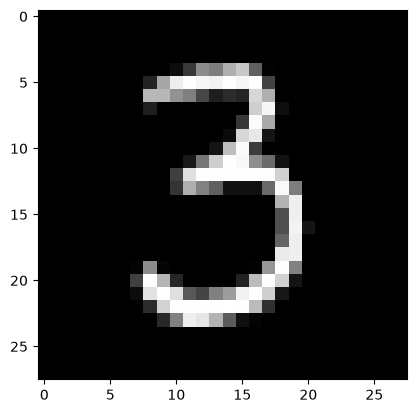

In [4]:
#collapse
plt.imshow(x_train[50].reshape(28,28), cmap="gray");
x_train[50]

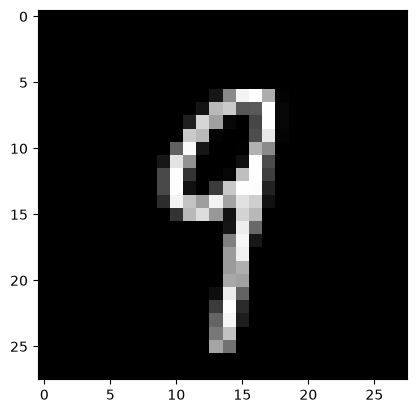

In [5]:
#collapse
plt.imshow(x_train[900].reshape(28,28), cmap="gray");

## Энгийн загварын архитектур

Энэ даалгаврын хувьд бид энэ 2 шугаман давхарга, 10 нэгж бүхий гаралтын давхаргыг маш энгийн загварын архитектурыг ашиглах болно.

🔧 Засвар: системд dot байхгүй. Зургийн нүдийг guard-тай болгож, эхийн ExecutableNotFound алдааг арилгав. Анхны notebook-д хадгалсан SVG зураг байгаагүй; оронд нь диаграммын эх текстийг харуулна.

In [6]:
#hide_input
import graphviz
import shutil
def gv(s):
    if shutil.which('dot'):
        return graphviz.Source('digraph G{ rankdir="LR"' + s + '; }')
    print('dot байхгүй; диаграммын эх текст:')
    print(s)


## Энэ сүлжээ гэдэг нь юу гэсэн үг болохыг илүү дэлгэрэнгүй авч үзье:

🔧 Засвар: sigmoid-ийн exp доторх хасах тэмдэг дутуу байсныг засав.

Энэ сүлжээний бүх бүрэлдэхүүн хэсгүүдийг авч үзье:
- **Linear:**
  Шугаман давхарга нь дараах тооцооллыг хийнэ:      
   ```
   out = matmul(input,W1) + B1
   ```
   
- **ReLU:**
  ReLU нь дараах тооцооллыг хийнэ:
  ```
  out = max(0, input)
  ```
- **Sigmoid:**
  Sigmoid нь дараах тооцооллыг хийнэ:
  ```
  out = 1/(1 + e.pow(-input))
  ```
  
- **Loss:**
  Бид алдагдалд дараах тэгшитгэлээр тодорхойлогдсон CrossEntropy алдагдлыг ашиглах болно:
  $$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

**Одоо бид өөрсдийн загвар архитектуртай болсноор загварыг цуглуулахад шаардлагатай хэсгүүдийг бүтээцгээе:**
- linear layer
- relu activation
- sigmoid activation
- loss

**Эхлээд загварынхаа арагшаа, урагшаа дамжаанд юу болж байгааг ойлгохыг хичээе:**

🔧 Засвар: эхний Linear-ийн псевдокод w2/b2 биш w1/b1 ашиглах ёстой.

**Судалгааны ажилын дагуу бидний загвар дараах байдалтай байна:**

> Тэмдэглэгээ: `@` python-д  `matrix-multiplication operator`.

```python
inputs = x_train # оролтууд
targets = y_train # шошго

# 1-р шугаман давхаргад урагш тархалт
z1 = inputs @ w1 + b1
a1 = relu(z1)
# 2-р шугаман давхаргад урагш тархалт
z2 = a1 @ w2 + b2
a2 = relu(z2)
# гаралт шугаман давхаргад урагш тархалт
z3 = a2 @ w3 + b3
pred = a3 = sigmoid(z3) # эдгээр нь бидний загварын таамаглалууд
# шошго болон таамаглалуудаас алдааг тодорхойлох
loss = loss_fn(a3, targets)
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Урагш буюу шууд тархалт :**

In [7]:
#hide_input
gv('''
X->linear1->relu1->linear2->relu2->linear3->sigmoid->prediction

W1->linear1
B1->linear1

W2->linear2
B2->linear2

W3->linear3
B3->linear3
''')

dot байхгүй; диаграммын эх текст:

X->linear1->relu1->linear2->relu2->linear3->sigmoid->prediction

W1->linear1
B1->linear1

W2->linear2
B2->linear2

W3->linear3
B3->linear3



In [8]:
#hide_input
gv('''
prediction->loss_fn
target->loss_fn
loss_fn-> loss
''')

dot байхгүй; диаграммын эх текст:

prediction->loss_fn
target->loss_fn
loss_fn-> loss



**Мөн буцах буюу гэдрэг тархалт нь дараах байдалтай байна : (Гинжэн дүрэм)**

(Let us assume that the `grad(inp, out)` computes the gradients of `inp` wrt `out`)
(`grad(inp, out)` нь `inp`, `out` гэх мэтийн градиентуудыг тооцоолдог гэж бодъё)

```python
# сүүлийн идэвхжүүлэх давхаргын гаралтын алдагдлын gradient: (a3)
# (өөрөөр загварын таамаглалтууд)
da3 = grad(loss, a3)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z3)
dz3 = grad(loss, z3) = grad(loss, a3) * grad(a3, z3)
# алдагдлын градиент w3 хүртэл
dw3 = grad(loss, w3) = grad(loss, z3) * grad(z3, w3) = dz3 * grad(z3, w3)
# алдагдлын градиент b3 хүртэл
db3 = grad(loss, b3) = grad(loss, z3) * grad(z3, b3) = dz3 * grad(z3, b3)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a2)
da2 = grad(loss, a2) = grad(loss, a3) = grad(a2, )

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z2)
dz2 = grad(loss, z2) = grad(loss, a2) * grad(a2, z2)
# алдагдлын градиент w2 хүртэл
dw2 = grad(loss, w2) = grad(loss, z2) * grad(z2, w2) = dz2 * grad(z2, w2)
# алдагдлын градиент b2 хүртэл
db2 = grad(loss, b2) = grad(loss, z2) * grad(z2, b2) = dz2 * grad(z2, b2)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a1)
da1 = grad(loss, a1) = grad(loss, z2) * grad(z2, a1) = dz2 * grad(z2, a1)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z1)
dz1 = grad(loss, z1) = grad(loss, a1) * grad(a1, z1) = da1 * grad(a1, z1)
# алдагдлын градиент w1 хүртэл
dw1 = grad(loss, w1) = grad(loss, z1) * grad(z1, w1) = dz1 * grad(z1, w1)
# алдагдлын градиент b1 хүртэл
db1 = grad(loss, b1) = grad(loss, z1) * grad(z1, 1) = dz1 * grad(z1, b1)
# Энэ давхаргад оролтууд нь бид илүү олон градиентыг тооцоолол хийх шаардлагагүй тулд бидний өөрчилж чадахгүй сургалтын жишээнүүд юм.

# parameter-үүдийг шинэчлэх :
# одоо бидэнд шаардлагатай бүх градиент байгаа болохоор бид одоо шинэчлэх алхмыг хийж болно.
w1 -= learning_rate * dw1
b1 -= learning_rate * db1

w2 -= learning_rate * dw2
b2 -= learning_rate * db2
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Буцах чиглэл:**

In [9]:
#hide_input
gv('''
Loss -> sigmoid->linear3
linear3->W3
linear3->B3
linear3->relu2->linear2

linear2->W2
linear2->B2
linear2->relu1->linear1

linear1->W1
linear1->B1
''')

dot байхгүй; диаграммын эх текст:

Loss -> sigmoid->linear3
linear3->W3
linear3->B3
linear3->relu2->linear2

linear2->W2
linear2->B2
linear2->relu1->linear1

linear1->W1
linear1->B1



### `Linear` давхарга

Доорх код нь бидний мэдрэлийн сүлжээнд `Linear` давхаргыг төлөөлдөг `Linear class` үүсгэдэг. Ангийн `forward function` нь `layer's forward propagation` -ийг хэрэгжүүлдэг & `backward function` нь `layers's backward propagation` хэрэгжүүлдэг. Код гэж юу болохыг нарийвчлан авч үзье:

- **Forward:**  
Энэ хэсэг нь шууд шулуунаар нь **`input`**  болон **`weights`**-ын хооронд dot-product-г тооцоолдог . **`z`** болон **`bias`** нэр томъёог нэмдэг. Мөн backward чиглэлд ашиглахын тулд бий болсон утгуудыг бүгдийг нь хадгалдаг.

- **Backward:**
    * Ангийн **`Linear`**-ын буцаах арга нь **`grads`** гэсэн аргументад ордог.
    * **`grads`** гэдэг нь одоогийн шугаман давхаргийн гаралт руу гарах алдагдлын градиент юм. **`dz`** хэрэв бид псевдо-кодоо дагаж гүйцэтгэх болно.
    * Шугаман давхаргадаа арагшаа тооцоолохын тулд бидэнд дараах зүйл хэрэгтэй:
        - **`grad(z, w)`**
        - **`grad(z, b)`**
        - **`grad(z, a_prev)`**


> Тэмдэглэл: `z`, `w`, `b`, `a_prev` гэдэг нь Linear давхаргын гаралт, жин, bias болон оролт-идэвхжүүлэлтийг тус тус хэлдэг.

🔧 Засвар: Linear.backward шинжийн тоонд биш batch-ын m=inp.shape[0]-д хуваана. Градиентыг давхар бүрт давхар дундажлахгүй: loss.backward болон дамжих da нь дээж тус бүрийн уламжлал, dw/db нь batch-ын дундаж. Debug хэвлэлтийг арилгав.

In [10]:
class Linear:
    def __init__(self, w, b):
        self.w = w
        self.b = b

    def forward(self, inp):
        """
        Давхаргын урагшлах тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
        inp : өмнөх давхаргын идэвхжүүлэлт (эсвэл оролтын өгөгдөл)
        Буцаах нь:
        z : идэвхжүүлэх функцийн оролт, мөн урьдчилан идэвхжүүлэх параметр гэж нэрлэдэг
        """
        self.inp = inp
        self.z   = np.matmul(inp, self.w) +self.b
        return self.z

    def backward(self, grads):
        """
        Нэг давхаргад арагшаа тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
        grads : шугаман гаралттай холбоотой зардлын Грэйдиент.
        эсвэл prev давхаргаас хуримтлагдсан градиентууд.
        Энэ нь гинжний дүрэмд градиентуудыг тооцоолоход ашиглагддаг.
        Буцаах нь:
        да: өмнөх давхаргын идэвхжүүлэлт эсвэл оролт руу зардлын одоогийн давхаргын Gradient        .
        dw: W-тэй холбоотой зардлын градиент
        db : b-тэй холбоотой зардлын градиент
        """
        m = self.inp.shape[0]
        # жингүүдийн алдагдлын градиент

        dw = np.matmul(self.inp.T, grads) / m # 16x10 w3
        # bias-уудын алдагдлын градиент
        db = grads.sum(axis=0, keepdims=True) / m
        # алдагдлын шугаман давхаргын оролтод энэ нь гинжний дүрмийг үргэлжлүүлэхэд хэрэглэгддэг
        da_prev = np.matmul(grads, self.w.T)
        return (da_prev, dw, db)

### `ReLU` давхарга

- **Forward**:  
ReLU-ийн математик томъёо нь $A = RELU(Z) = max(0, Z)$
- **Backward**:  
Буцах дамжлагын үед relu нь `loss activation` буюу `da` гэсэн градиентуудыг хүлээн зөвшөөрч дараа нь `loss input-of-relu(z)` i.e, `dz` гэж тооцоолоно.

In [11]:
class RelU:
    def forward(self, inp):
        """
        RELU функцийг хэрэгжүүлэлт.

        аргумент:
            inp : Шугаман давхаргын гаралт, ямар ч хэлбэрт

        Буцаах:
            a  : Идэвхжүүлэлтийн дараах параметр, Z-тэй ижил хэлбэртэй
        """
        self.inp = inp
        self.output = np.maximum(0, self.inp)
        return self.output

    def backward(self, grads):
        """
        Нэг RELU нэгжийг буцах тархалтыг хэрэгжүүлнэ.

        аргумент:
            grads : алдагдлын градиентууд идэвхжүүлэлтийн гаралт руу

        Буцаах:
            dz : Идэвхжүүлэлтийн оролттой холбоотой алдагдлын градиент
        """
        dz = np.array(grads, copy=True)
        dz[self.inp <= 0] = 0
        return dz

### `sigmoid` давхарга

Sigmoid давхарга нь `ReLU` давхаргатай яг ижил байдлаар үйл ажиллагаа хийгддэг ба ялгаа нь урагш дамжуулах гаралтын тооцоо юм.

`sigmoid layer`-д: $\sigma(Z) = \frac{1}{ 1 + e^{-(W A + b)}}$

🔧 Засвар: exp overflow-оос хамгаалж sigmoid-ийн оролтыг хязгаарлав; давталт бүрийн debug хэвлэлтийг арилгав.

In [12]:
class Sigmoid:
    def forward(self, inp):
        """
        sigmoid идэвхжүүлэлтийг хэрэгжүүлнэ

        аргумент:
            inp: Шугаман давхаргын гаралт, ямар ч хэлбэрт

        Буцаах:
            a  : sigmoid(z), inp-тэй адил хэлбэрийг гаргах
        """
        self.inp = inp
        self.out =  1/(1+np.exp(-np.clip(self.inp, -80, 80)))
        return self.out

    def backward(self, grads):
        """
        Нэг сигмоид нэгжийг буцах чиглэлийн үржүүлэгийг хэрэгжүүлнэ.

        аргумент:
            grads : алдагдлын градиентууд идэвхжүүлэлтийн гаралт руу

        Буцаах:
            dz : Идэвхжүүлэлтийн оролттой холбоотой алдагдлын градиент
        """
        s = np.array(self.out)
        dz = grads * s * (1 - s)
        return dz

## `Loss` функц :

Энэ даалгаварт бид [CrossEntropy Loss](https://en.wikipedia.org/wiki/Cross_entropy)-ийг ашиглана.


CrossEntropy Loss-ийн `forward` дамжуулалтыг дараах байдлаар тооцоолжээ.

$$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

CrossEntropy Loss-ийн `backward` дамжуулалтыг дараах байдлаар тооцоолжээ.
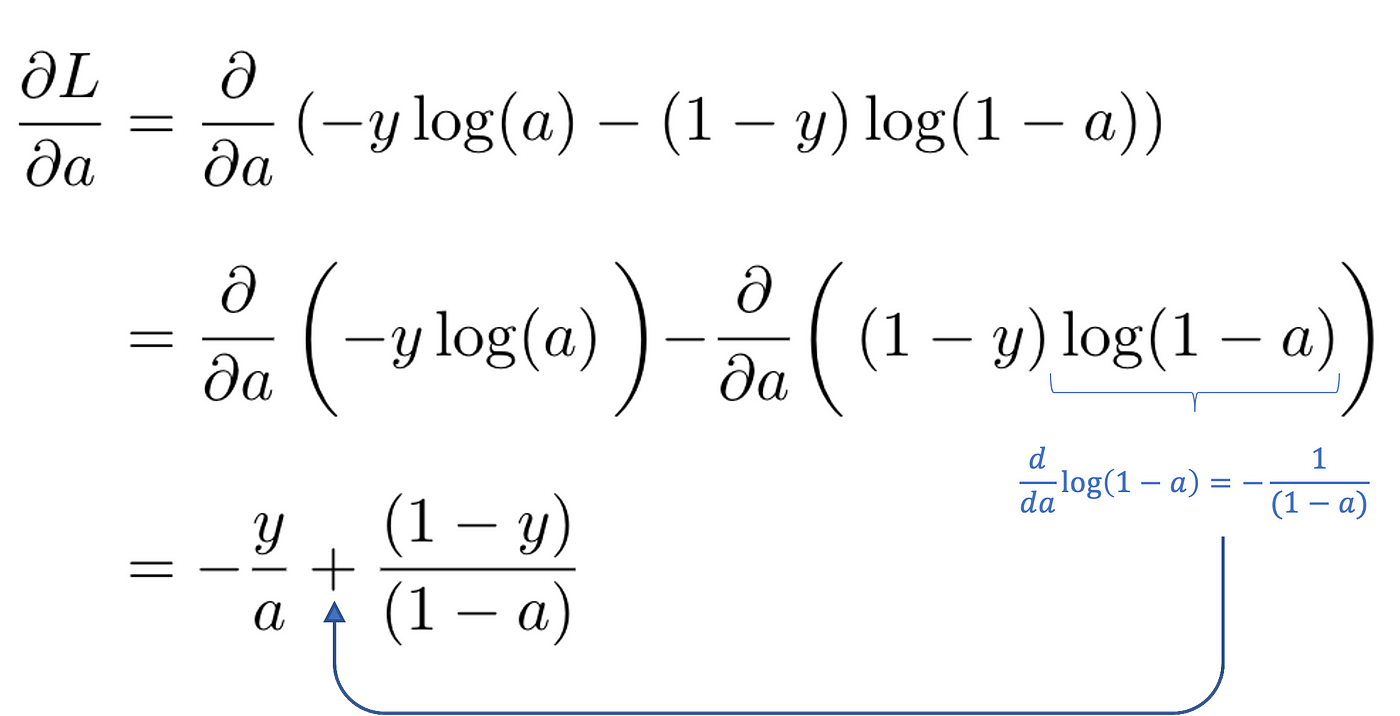

🔧 Засвар: CrossEntropy тэмдгийн алдаа (−term1 + term2), scalar биш гаралтыг засав. Sigmoid-ийн 10 гаралтад нэг-халуун зорилтот binary cross-entropy-г ангиар нийлүүлж batch-аар дундажлав; энэ нь softmax CE-ээс өөр. log(0)-оос хамгаалсан. backward нь дээж тус бүрийн уламжлал; Linear dw/db дээр нэг удаа дундажлана.

In [13]:
class CELoss():
    def forward(self, pred, target):
        """
        CrossEntropy алдагдлын функцийг хэрэгжүүлнэ.

        аргумент:
            pred   : мэдрэлийн сүлжээнээс урьдчилан таамагласан шошгуудыг
            target : үнэн шошго
        Буцаах:
            loss   : cross-entropy loss
        """
        self.yhat = np.clip(pred, 1e-7, 1-1e-7)
        self.y = target
        m = self.y.shape[0]
        # алдагдлыг тооцоолох
        term1 = self.y * np.log(self.yhat)
        term2 = (1-self.y) * np.log(1-self.yhat)
        loss = -(term1 + term2).sum() / m
        self.output = loss
        return np.squeeze(self.output) # array-г нэг утганд хөрвүүлэх

    def backward(self):
        """
        loss_fn -ийн градинетуудыг урьдчилан таамагласан шошго руу тооцоолдог

        Буцаах:
         da : урьдчилан таамагласан шошгуудын уламжлал
        """
        # [урьдчилан таамагласан шошготой] холбоотой loss_fn уламжлал
        da = - self.y / self.yhat + (1 - self.y) / (1 - self.yhat)
        return da

## Загвар:

**Одоо ашиглах гэж байгаа мэдрэлийн сүлжээний архитектурыг хэрэгжүүлцгээе:**

- Манай загвар нь 2 далд давхарга, гаралтын давхаргатай болно.
- 2 `hidden layers` `(linear layers)` нь тус бүрдээ `16 units` дараа нь `ReLU` идэвхжүүлэх давхарга, `output layer` `(linear layers)` нь `10 unit` дараа нь `Sigmoid` давхаргуудтай болно.

Загварыг бүтээхэд шаардагдах давхаргуудыг цуглуулъя:

Shape of Inputs: (60000, 784)
Shape of Targets: (60000, 10)


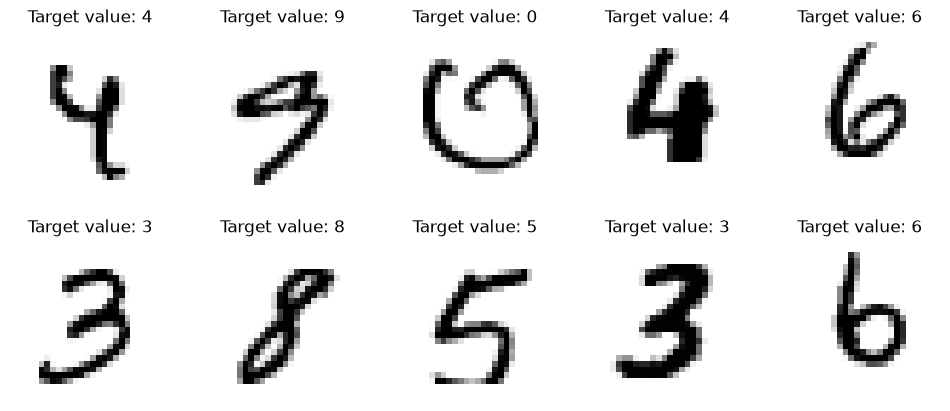

In [14]:
#collapse
print("Shape of Inputs:", x_train.shape)
print("Shape of Targets:", y_train.shape)

fig = plt.figure(figsize=(12,5))
for i in range(10):
    n = np.random.randint(len(x_train))
    val = x_train[n]
    ax = plt.subplot(2, 5, i+1)
    plt.imshow(val.reshape(28,28), cmap="binary")
    plt.title(f"Target value: {np.argmax(y_train[n])}")
    plt.axis("off")

**Initialize model parameters:**

In [15]:
#hide_output

nh1 = 16 # эхний нуугдмал давхарга дахь нэгжүүд
nh2 = 16 # 2-р нуугдмал давхарга дахь нэгжүүд
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

((784, 16), (1, 16), (16, 16), (1, 16), (16, 10), (1, 10))

**Манай загварыг бүтээхэд шаардлагатай давхаргуудыг давхарлая :**

In [16]:
lin1    = Linear(w1,b1) # 1 hidden layer
relu1   = RelU()
lin2    = Linear(w2,b2) # 2nd hidden layer
relu2   = RelU()
lin3    = Linear(w3,b3) # output layer
sigmoid = Sigmoid()

loss_fn = CELoss() # loss_fn

### Шууд чиглэл:

In [17]:
# forward pass
z1   = lin1.forward(x_train[:50])
a1   = relu1.forward(z1)
z2   = lin2.forward(a1)
a2   = relu2.forward(z2)
z3   = lin3.forward(a2)
pred = a3 = sigmoid.forward(z3)
# print(pred)
# calculate loss
loss = loss_fn.forward(pred, y_train[:50])
print("Loss:", loss)

Loss: 6.935105327326305


### Буцах чиглэл:

🔧 Засвар: эхний Linear давхаргад ReLU-ийн өмнөх da1 биш дараах dz1 дамжуулах ёстой. Гинжин дүрмийг засав.

In [18]:
# backward pass
da3 = loss_fn.backward() # gradient of loss wrt to final output

dz3 = sigmoid.backward(da3)

da2, dw3, db3 = lin3.backward(dz3)

dz2 = relu2.backward(da2)
da1, dw2, db2 = lin2.backward(dz2)

dz1 = relu1.backward(da1)
_, dw1, db1 = lin1.backward(dz1)

# параметрүүд болон градиентууд ижил хэлбэртэй эсэхийг шалгах.
# Ингэснээр бид шинэчлэлтийн байдлыг урьдчилан харж чадна
assert lin1.w.shape == dw1.shape
assert lin2.w.shape == dw2.shape
assert lin3.w.shape == dw3.shape

assert lin1.b.shape == db1.shape
assert lin2.b.shape == db2.shape
assert lin3.b.shape == db3.shape

### parameter-үүдийг шинэчлэх:

In [19]:
# сургах хурдыг тохируулах
learning_rate = 0.0002


lin1.w -= learning_rate * np.array(dw1)
lin2.w -= learning_rate * np.array(dw2)
lin3.w -= learning_rate * np.array(dw3)

lin1.b -= learning_rate * np.array(db1)
lin2.b -= learning_rate * np.array(db2)
lin3.b -= learning_rate * np.array(db3)

Тэгэхээр, бидний загварыг сургахад эхлээд `forward pass`-ийн үед загварын `loss`-ыг тооцоолж, дараа нь загварын `parameters` руу `loss`-ийн градиентуудыг тооцоолдог. Үүний дараа эдгээр `gradients` нь `update the model parameters` ашиглагддаг. Бид энэхүү ажлын урсгалыг тодорхой тооны `iterations` эсвэл бидний `loss` хүссэн утганд хүрэх хүртэл үргэлжлүүлсээр байдаг.


Энэ алхмуудыг хэрэгжүүлцгээе.

### Бүгдийг нэгтгэвэл:

- **parameter-үүдийг эхлүүлэх:**

🔧 Засвар: маш жижиг эхлэл ба 10 бүтэн-batch алхам нь хангалтгүй. Ижил 256→64→10 архитектурыг He эхлэлтэй float32 жингээр, мини-batch SGD-ээр сургана; NumPy/CuPy ижил эхлэл, batch дараалал хэрэглэнэ.

In [20]:
#hide_output

nh1 = 256 # эхний нуугдмал давхарга дахь нэгжүүдийн
nh2 = 64 # 2-р нуугдмал давхарга дахь нэгжүүдийн
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

np.random.seed(42)
w1  = (np.random.randn(x_train.shape[1], nh1) * np.sqrt(2/x_train.shape[1])).astype(np.float32)
b1  = np.zeros((1, nh1), dtype=np.float32)

w2  = (np.random.randn(nh1, nh2) * np.sqrt(2/nh1)).astype(np.float32)
b2  = np.zeros((1, nh2), dtype=np.float32)

w3  = (np.random.randn(nh2, nh3) * np.sqrt(1/nh2)).astype(np.float32)
b3  = np.zeros((1, nh3), dtype=np.float32)

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

((784, 256), (1, 256), (256, 64), (1, 64), (64, 10), (1, 10))

Загварт зориулж 'Model' class бий болгох.

Энэ `Model` class нь манай мэдрэлийн сүлжээний бүх параметрүүдийг хадгалах болно. `forward` арга нь тухайн загварын `loss` (болон `predictions`) үүсгэхийн тулд сүлжээний `forward pass`-ийг тооцоолно. `backward` арга нь `loss`-ийн градинетуудыг загварын `parameters` хүргэхийн тулд сүлжээний `backward pass` тооцоолно. Эцэст нь `update` арга нь загварын параметрүүдийг шинэчлэх болно.

🔧 Засвар: Model._assert_shapes нь глобал хуучин dw/db-г шалгаж байсан. Одоо тухайн backward-ийн self.dws/dbs-г шалгана; загвар бүр жингийн хуулбартай. Анхны тооцооллын архитектурыг хадгалсан.

In [21]:
class Model:
    def __init__(self, learning_rate):
        """
        энгийн нерон сүлжээ
        `forward` загварын шууд тархалтыг тооцоолно
        `backward` загварын буцах тархалтыг тооцоолно
        `update_step` загварын парамертрүүдийг шинэчлэнэ
        """
        self.lin1    = Linear(w1.copy(),b1.copy()) # 1-р шугаман давхарга
        self.relu1   = RelU()        # 1-р идэвхжүүлэх давхарга

        self.lin2    = Linear(w2.copy(),b2.copy()) # 2-р шугаман давхарга
        self.relu2   = RelU()        # 2-р идэвхжүүлэх давхарга

        self.lin3    = Linear(w3.copy(),b3.copy()) # 3-р шугаман давхарга
        self.sigmoid = Sigmoid()     # 3-р идэвхжүүлэх давхарга

        self.loss_fn = CELoss()      # loss_fn

        # сургалтын хурд
        self.lr      = learning_rate
        # алдааг алхам бүрт хадгална
        self.losses  = []


    def forward(self, inp, calc_loss=True, targ=None):
        """
        Загварыг урагшлах алхмыг тооцоол. Нэмэлтээр энэ нь мөн алдагдлыг болон загварын урьдчилан таамаглалыг буцааж өгдөг.

        аргумент:
            inp       : сургалтын сан.
            calc_loss : зөвхөн урьдчилан таамаглал тооцоолдог бол загварын алдагдлыг тооцохгүй байх
            targ      : шошгууд.

        Тайлбар: ''алдагдал''-ыг тооцохын тулд 'шошго' заавал өгөх ёстой

        Буцаах:
            pred : 3-р идэвхжүүлэлтийн давхаргын үр дүн.
            loss : загвараа алдах , хэрэв 'шошго' өгөгдсөн бол.
        """
        out  = self.lin1.forward(inp)
        out  = self.relu1.forward(out)
        out  = self.lin2.forward(out)
        out  = self.relu2.forward(out)
        out  = self.lin3.forward(out)
        pred = self.sigmoid.forward(out)

        if calc_loss:
            assert targ is not None, "алдагдлыг тооцохын тулд заавал өгөх ёстой"
            loss = self.loss_fn.forward(pred, targ)

            self.losses.append(loss)
            return loss, pred
        else:
            return pred

    def _assert_shapes(self):
        for layer, dw, db in zip([self.lin1, self.lin2, self.lin3], self.dws, self.dbs):
            assert layer.w.shape == dw.shape
            assert layer.b.shape == db.shape


    def backward(self):
        """
        Буцах алхмыг тооцоолж, параметрүүдийн градиентуудыг алдагдалтай буцааж өгдөг
        """
        da3 = np.array(self.loss_fn.backward())
        dz3 = self.sigmoid.backward(da3)
        da2, dw3, db3 = self.lin3.backward(dz3)

        dz2 = self.relu2.backward(da2)
        da1, dw2, db2 = self.lin2.backward(dz2)

        dz1 = self.relu1.backward(da1)  
        _, dw1, db1 = self.lin1.backward(dz1)


        self.dws = [dw1, dw2, dw3]
        self.dbs = [db1, db2, db3]
        self._assert_shapes()


    def update(self):
        """
        Шинэчлэх алхмыг гүйцэтгэнэ
        """
        self.lin1.w -= self.lr * self.dws[0]
        self.lin2.w -= self.lr * self.dws[1]
        self.lin3.w -= self.lr * self.dws[2]

        self.lin1.b -= self.lr * self.dbs[0]
        self.lin2.b -= self.lr * self.dbs[1]
        self.lin3.b -= self.lr * self.dbs[2]

✅ Даалгавар 1 — Тоон градиентын бие даасан шалгалт

Төвийн ялгавраар Linear-ийн бүх жин/bias ба бүхэл сүлжээний давхарга бүрийн сонгосон жинг шалгана. float64 жижиг туршилт нь float32-ийн хасалтын алдааг багасгана.

In [22]:
rng_check = np.random.default_rng(7)
A = rng_check.normal(size=(4,3))
W = rng_check.normal(size=(3,2))
B = rng_check.normal(size=(1,2))
upstream = rng_check.normal(size=(4,2))
layer_check = Linear(W.copy(), B.copy())
layer_check.forward(A)
_, dW, dB = layer_check.backward(upstream)
def scalar_linear(): return np.sum((A @ layer_check.w + layer_check.b)*upstream)/len(A)
eps = 1e-5
errors = []
for parameter, analytic in [(layer_check.w, dW), (layer_check.b, dB)]:
    for index in np.ndindex(parameter.shape):
        old = parameter[index]
        parameter[index] = old + eps; plus = scalar_linear()
        parameter[index] = old - eps; minus = scalar_linear()
        parameter[index] = old
        errors.append(abs((plus-minus)/(2*eps)-analytic[index]))
assert max(errors) < 1e-8
probe_nn = Model(0.1)
for lyr in [probe_nn.lin1, probe_nn.lin2, probe_nn.lin3]:
    lyr.w = lyr.w.astype(np.float64); lyr.b = lyr.b.astype(np.float64)
probe_x = x_train[:5].astype(np.float64)
probe_y = y_train[:5].astype(np.float64)
probe_nn.forward(probe_x, targ=probe_y); probe_nn.backward()
network_errors = []
for lyr, dw, db in zip([probe_nn.lin1, probe_nn.lin2, probe_nn.lin3], probe_nn.dws, probe_nn.dbs):
    for parameter, gradient in [(lyr.w, dw), (lyr.b, db)]:
        for index in [tuple(0 for _ in parameter.shape), tuple(s-1 for s in parameter.shape)]:
            old = parameter[index]
            parameter[index] = old+eps; plus = probe_nn.forward(probe_x, targ=probe_y)[0]
            parameter[index] = old-eps; minus = probe_nn.forward(probe_x, targ=probe_y)[0]
            parameter[index] = old
            network_errors.append(abs((plus-minus)/(2*eps)-gradient[index]))
assert max(network_errors) < 1e-6
print('Linear max gradient error:', max(errors))
print('Network max gradient error:', max(network_errors))

Linear max gradient error: 2.0282081569789057e-11
Network max gradient error: 7.426619735850792e-11


✅ Даалгавар 1 — Бүх 60000 сургалтын зурагт 8 эпох мини-batch сургалт. Тестийн үр дүнгээр epoch сонгоогүй. Сургалтын цэвэр хугацааг ханын цагаар хэмжинэ.

In [23]:
nn = Model(learning_rate=0.15)
epochs = 8
batch_size_numpy = 256
initial_params = {f'{kind}{j}': getattr(layer, kind).copy()
                  for j, layer in enumerate([nn.lin1, nn.lin2, nn.lin3], 1) for kind in ['w','b']}
training_orders = [np.random.default_rng(100+epoch).permutation(len(x_train)) for epoch in range(epochs)]
# Жижиг BLAS халаалт нь NumPy хэмжилтийн эхлэх зардлыг багасгана.
_ = x_train[:batch_size_numpy] @ w1
numpy_start = perf_counter()
for n, order in enumerate(training_orders):
    epoch_loss = 0.0
    for start in range(0, len(order), batch_size_numpy):
        ids = order[start:start+batch_size_numpy]
        loss, _ = nn.forward(x_train[ids], calc_loss=True, targ=y_train[ids])
        nn.backward()
        nn.update()
        epoch_loss += float(loss)*len(ids)
    print(f'Epoch {n+1}/{epochs}: train BCE = {epoch_loss/len(order):.4f}')
numpy_train_seconds = perf_counter()-numpy_start
print('NumPy training seconds:', numpy_train_seconds)


Epoch 1/8: train BCE = 0.9886
Epoch 2/8: train BCE = 0.4288


Epoch 3/8: train BCE = 0.3206
Epoch 4/8: train BCE = 0.2609


Epoch 5/8: train BCE = 0.2192
Epoch 6/8: train BCE = 0.1889


Epoch 7/8: train BCE = 0.1657
Epoch 8/8: train BCE = 0.1475
NumPy training seconds: 1.582151234997582


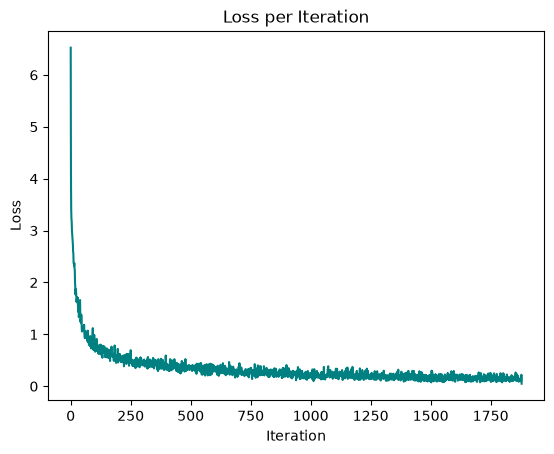

In [24]:
#collapse
plt.plot(nn.losses, color="teal")
plt.title("Loss per Iteration")
plt.xlabel("Iteration")
plt.ylabel("Loss");

## Загварын үнэн зөвийг тооцоолох

**'Баталгаажуулах' датасет дээр ''үнэн зөв''-ийг тооцоолон загвар үзүүлэлтээ шалгая**

Сургалтын багц дээрх үнэн зөв

✅ Даалгавар 1 — Сургалтын accuracy-г хадгална; нэг-халуун шошгыг эндээс ангийн индекст шилжүүлж, дараагийн хэсгүүдийг үүнтэй нийцүүлсэн.

In [25]:
preds = nn.forward(x_train, calc_loss=False) # загвараас таамаглалуудыг үүсгэх
# accuracy тооцоолох
print(preds.shape, y_train.shape)
preds=np.argmax(preds, axis=1)
y_train=np.argmax(y_train, axis=1)
print(preds.shape, y_train.shape)

acc = np.sum(preds==y_train)/len(y_train)
print(acc)
numpy_train_accuracy = float(acc)

(60000, 10) (60000, 10)
(60000,) (60000,)
0.9831


In [26]:
print(preds[0], y_train[0])

5 5


Баталгаажуулах багц дээрх үнэн зөв

✅ Даалгавар 1 — Албан тестийн accuracy-г хадгалж, дараа нь дахин ачаалсан загвартай харьцуулна.

In [27]:
preds = nn.forward(x_test, calc_loss=False) # загвараас таамаглалуудыг үүсгэх
# accuracy тооцоолох
preds=np.argmax(preds, axis=1)
y_test=np.argmax(y_test, axis=1)
acc = np.sum(preds==y_test)/len(y_test)
print(acc)
numpy_test_accuracy = float(acc)
assert numpy_test_accuracy >= 0.90

0.9743


🔧 Засвар: хуучин 0.60 нарийвчлалын мэдэгдлийг бодит ажиллуулалтын тайлбараар сольсон; сургалтын сан ба албан тестийн санг ялгав.

NumPy загварын сургалтын болон тестийн бодит accuracy-г өмнөх нүднүүдэд хэвлэв. Доор тухайн хэмжилтэд тулгуурласан дүгнэлт гаргана. MNIST-ийн албан тестийн 10000 зураг нь сургалтад ороогүй.

✅ Даалгавар 1 — NumPy дүгнэлт, жинг хадгалж дахин ачаалах

In [28]:
np.savez('numpy_nn_weights.npz', architecture=np.array([784,256,64,10]), normalization='pixel/255', activations=np.array(['relu','relu','sigmoid']), loss='sum binary CE per example; batch mean', classes=np.arange(10), test_accuracy=numpy_test_accuracy, epochs=epochs, batch_size=batch_size_numpy, **{f'{kind}{j}': getattr(layer, kind) for j, layer in enumerate([nn.lin1,nn.lin2,nn.lin3],1) for kind in ['w','b']})
loaded_numpy = Model(learning_rate=0.15)
with np.load('numpy_nn_weights.npz', allow_pickle=False) as z:
    for j, layer in enumerate([loaded_numpy.lin1, loaded_numpy.lin2, loaded_numpy.lin3],1):
        layer.w = z[f'w{j}']; layer.b = z[f'b{j}']
reloaded_numpy_acc = accuracy_score(y_test, loaded_numpy.forward(x_test, calc_loss=False).argmax(axis=1))
assert reloaded_numpy_acc == numpy_test_accuracy
saved_model_files.append('numpy_nn_weights.npz')
print('NumPy дахин ачаалсан accuracy:', reloaded_numpy_acc)
display(Markdown(f'NumPy сургалтын accuracy **{numpy_train_accuracy:.4f}**, тестийн accuracy **{numpy_test_accuracy:.4f}**, сургалтын хугацаа **{numpy_train_seconds:.2f} секунд**. Алдагдал буурсан ба зөв зассан гэдрэг тархалт нь санамсаргүй 0.1-ээс илүү үр дүнд хүрлээ. Хадгалсан жингээс тестийн үр дүн яг давтагдав.'))

NumPy дахин ачаалсан accuracy: 0.9743


NumPy сургалтын accuracy **0.9831**, тестийн accuracy **0.9743**, сургалтын хугацаа **1.58 секунд**. Алдагдал буурсан ба зөв зассан гэдрэг тархалт нь санамсаргүй 0.1-ээс илүү үр дүнд хүрлээ. Хадгалсан жингээс тестийн үр дүн яг давтагдав.

## Загвараас таамаглалуудыг үүсгэх

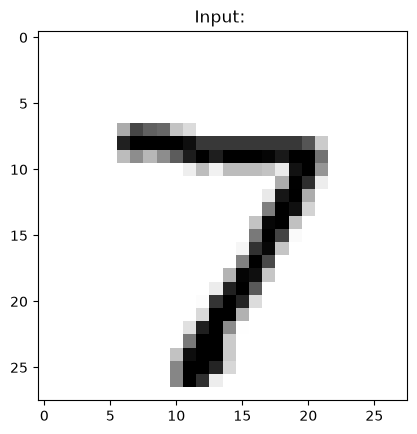

Predicted output: 7


In [29]:
#collapse
test_inp = x_test[0] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")

plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

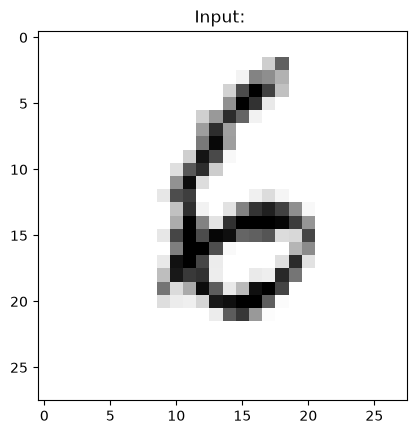

Predicted output: 6


In [30]:
#collapse
test_inp = x_test[2000] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")
plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

# 2-р хэсэг
# CuPy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.



✅ Даалгавар 2 — CuPy GPU сүлжээ

Linear, ReLU, Sigmoid, BCE болон Model-ийн forward/backward/update нь зөвхөн CuPy ndarray ашиглана. NumPy-тай ижил float32 эхлэл, 60000 зураг, 8 эпох, batch=256, lr=0.15 болон batch дарааллаар харьцуулна. JIT халаалтыг хэмжилтээс өмнө хийж, GPU-г эхлэл/төгсгөлд synchronize хийнэ. Өгөгдөл шилжүүлэх хугацааг сургалтын хугацаанаас тусад нь хэмжинэ.

In [31]:
import cupy as cp
assert cp.cuda.runtime.getDeviceCount() > 0
print('CuPy device:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())
class CuLinear:
    def __init__(self, w, b): self.w, self.b = w.copy(), b.copy()
    def forward(self, inp):
        self.inp = inp
        self.z = inp @ self.w + self.b
        return self.z
    def backward(self, grads):
        return grads @ self.w.T, self.inp.T @ grads / len(grads), grads.mean(axis=0, keepdims=True)
class CuRelU:
    def forward(self, inp):
        self.inp = inp
        return cp.maximum(inp, 0)
    def backward(self, grads): return grads * (self.inp > 0)
class CuSigmoid:
    def forward(self, inp):
        self.out = 1/(1+cp.exp(-cp.clip(inp, -80, 80)))
        return self.out
    def backward(self, grads): return grads*self.out*(1-self.out)
class CuCELoss:
    def forward(self, pred, target):
        self.yhat, self.y = cp.clip(pred, 1e-7, 1-1e-7), target
        return -cp.sum(target*cp.log(self.yhat)+(1-target)*cp.log1p(-self.yhat))/len(target)
    def backward(self): return -self.y/self.yhat+(1-self.y)/(1-self.yhat)
class CuModel:
    def __init__(self, params, lr=0.15):
        self.layers = [CuLinear(params[f'w{j}'], params[f'b{j}']) for j in range(1,4)]
        self.activations = [CuRelU(), CuRelU(), CuSigmoid()]
        self.loss_fn, self.lr = CuCELoss(), lr
    def forward(self, inp, targ=None):
        for layer, activation in zip(self.layers, self.activations): inp = activation.forward(layer.forward(inp))
        if targ is None: return inp
        return self.loss_fn.forward(inp, targ), inp
    def backward(self):
        grads = self.loss_fn.backward()
        self.gradients = []
        for layer, activation in reversed(list(zip(self.layers, self.activations))):
            grads, dw, db = layer.backward(activation.backward(grads))
            self.gradients.insert(0, (dw, db))
    def update(self):
        for layer, (dw, db) in zip(self.layers, self.gradients):
            layer.w -= self.lr*dw; layer.b -= self.lr*db
cp.cuda.Device().synchronize()
transfer_start = perf_counter()
cu_X = cp.asarray(x_train)
cu_Y = cp.eye(10, dtype=cp.float32)[cp.asarray(y_train)]
cu_test_X = cp.asarray(x_test)
cu_params = {k: cp.asarray(v) for k,v in initial_params.items()}
cu_orders = [cp.asarray(order) for order in training_orders]
cp.cuda.Device().synchronize()
transfer_seconds = perf_counter()-transfer_start
# Ижил эхлэлтэй CPU/GPU forward/backward болон нэг update-ийг шалгана.
np_probe = Model(0.15)
cu_probe = CuModel(cu_params)
probe_labels = np.eye(10, dtype=np.float32)[y_train[:32]]
np_loss, np_pred = np_probe.forward(x_train[:32], targ=probe_labels)
cu_loss, cu_pred = cu_probe.forward(cu_X[:32], cu_Y[:32])
np.testing.assert_allclose(cp.asnumpy(cu_pred), np_pred, atol=2e-6)
for cpu_layer, gpu_layer in zip([np_probe.lin1,np_probe.lin2,np_probe.lin3], cu_probe.layers):
    np.testing.assert_allclose(cp.asnumpy(gpu_layer.z), cpu_layer.z, atol=2e-6)
assert np.isclose(float(cu_loss.get()), np_loss, atol=2e-6)
np_probe.backward(); cu_probe.backward()
for cpu_dw, cpu_db, (gpu_dw, gpu_db) in zip(np_probe.dws, np_probe.dbs, cu_probe.gradients):
    np.testing.assert_allclose(cp.asnumpy(gpu_dw), cpu_dw, atol=2e-6)
    np.testing.assert_allclose(cp.asnumpy(gpu_db), cpu_db, atol=2e-6)
np_probe.update(); cu_probe.update()
for cpu_layer, gpu_layer in zip([np_probe.lin1,np_probe.lin2,np_probe.lin3], cu_probe.layers):
    np.testing.assert_allclose(cp.asnumpy(gpu_layer.w), cpu_layer.w, atol=2e-6)
    np.testing.assert_allclose(cp.asnumpy(gpu_layer.b), cpu_layer.b, atol=2e-6)
print('NumPy/CuPy давхарга бүрийн гаралт, бүх dw/db ба нэг update тохиров.')
cu_nn = CuModel(cu_params)
cp.cuda.Device().synchronize()
cu_start = perf_counter()
cu_epoch_losses = []
for epoch, order in enumerate(cu_orders):
    total_loss = cp.zeros((), dtype=cp.float64)
    for start in range(0, len(order), batch_size_numpy):
        ids = order[start:start+batch_size_numpy]
        loss, _ = cu_nn.forward(cu_X[ids], cu_Y[ids])
        cu_nn.backward(); cu_nn.update()
        total_loss += loss*len(ids)
    cu_epoch_losses.append(total_loss/len(order))
cp.cuda.Device().synchronize()
cupy_train_seconds = perf_counter()-cu_start
cupy_test_pred = cp.asnumpy(cu_nn.forward(cu_test_X).argmax(axis=1))
cupy_test_accuracy = accuracy_score(y_test, cupy_test_pred)
print('CuPy epoch BCE:', [float(v.get()) for v in cu_epoch_losses])
print('CuPy test accuracy:', cupy_test_accuracy)
print('NumPy seconds:', numpy_train_seconds, 'CuPy seconds:', cupy_train_seconds,
      'speed-up:', numpy_train_seconds/cupy_train_seconds, 'transfer seconds:', transfer_seconds)
assert cupy_test_accuracy >= 0.90
assert abs(cupy_test_accuracy-numpy_test_accuracy) < 0.02
np.savez('cupy_nn_weights.npz', architecture=np.array([784,256,64,10]), normalization='pixel/255', activations=np.array(['relu','relu','sigmoid']), classes=np.arange(10), test_accuracy=cupy_test_accuracy, epochs=epochs, batch_size=batch_size_numpy, **{f'{kind}{j}': cp.asnumpy(getattr(layer,kind)) for j,layer in enumerate(cu_nn.layers,1) for kind in ['w','b']})
with np.load('cupy_nn_weights.npz', allow_pickle=False) as z:
    restored_cu = CuModel({k:cp.asarray(z[k]) for k in z.files if k[0] in ['w','b'] and k[1:].isdigit()})
assert np.array_equal(cp.asnumpy(restored_cu.forward(cu_test_X).argmax(axis=1)), cupy_test_pred)
saved_model_files.append('cupy_nn_weights.npz')
display(Markdown(f'Ижил сургалтын нөхцөлд CuPy тестийн accuracy **{cupy_test_accuracy:.4f}**; NumPy **{numpy_test_accuracy:.4f}**. GPU сургалт **{cupy_train_seconds:.2f} с**, CPU **{numpy_train_seconds:.2f} с**, харьцаа **{numpy_train_seconds/cupy_train_seconds:.2f}×**. Өгөгдөл шилжүүлэлт **{transfer_seconds:.3f} с**, JIT халаалт тусдаа. Энэ харьцаа зөвхөн энэ машин, batch ба архитектурт хамаарна. Дахин ачаалсан GPU загварын таамаглал яг таарав.'))
# PyTorch хэсэгт CuPy-ийн хэрэггүй завсрын том массивуудыг чөлөөлнө.
del cu_X, cu_Y, cu_test_X, cu_probe, restored_cu
cp.get_default_memory_pool().free_all_blocks()


CuPy device: NVIDIA GeForce RTX 5070 Ti


NumPy/CuPy давхарга бүрийн гаралт, бүх dw/db ба нэг update тохиров.


CuPy epoch BCE: [0.9887875890731812, 0.4288460319519043, 0.3206890989303589, 0.26076199572881065, 0.2189779291152954, 0.18870603070259095, 0.16556799538135528, 0.14730963215033213]
CuPy test accuracy: 0.9742
NumPy seconds: 1.582151234997582 CuPy seconds: 0.6257197579980129 speed-up: 2.528530088389196 transfer seconds: 0.06193844700101181


Ижил сургалтын нөхцөлд CuPy тестийн accuracy **0.9742**; NumPy **0.9743**. GPU сургалт **0.63 с**, CPU **1.58 с**, харьцаа **2.53×**. Өгөгдөл шилжүүлэлт **0.062 с**, JIT халаалт тусдаа. Энэ харьцаа зөвхөн энэ машин, batch ба архитектурт хамаарна. Дахин ачаалсан GPU загварын таамаглал яг таарав.

# 3-р хэсэг
# Pytorch ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.

🔧 Засвар: өгөгдсөн SimpleNN-ийн 512+512 салаалалт зөвхөн hidden1=1024 үед ажиллаж байсан. Салаалалтыг hidden1//2-оор, салааны гаралтыг hidden2-оор тодорхойлов. CrossEntropyLoss нь sigmoid биш logits, long ангийн шошго хүлээн авна. Model ба batch бүр CUDA дээр. Тестээр сонголт хийх 50-эпохын давталтыг тусдаа validation-тай суурь сургалтаар сольж, бодит хайлтыг 4-р хэсэгт хийв.

In [32]:
import torch
import torch.nn as nn
from torch.optim import SGD, AdamW
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import Compose, ToTensor

train_dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))
transform = Compose([ToTensor()])
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
class SimpleNN(nn.Module):
    def __init__(self, input_size=28*28, hidden_size1=256, hidden_size2=64, output_size=10):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden_size2, output_size)
        self.sigmoid = nn.Sigmoid()
        self.split = hidden_size1 // 2
        self.fc_b1 = nn.Linear(self.split, hidden_size2)
        self.fc_b2 = nn.Linear(hidden_size1-self.split, hidden_size2)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        # print(x.shape)
        x1, x2 = x[:, :self.split], x[:, self.split:]
        # print(x1.shape, x2.shape)
        x1 = self.fc_b1(x1)
        x2 = self.fc_b2(x2)
        x = self.fc2(x)

        x = self.relu2(x + x1 + x2)
        x = self.fc3(x)
        return x
def train_model(model, train_loader, criterion, optimizer, num_epochs, verbose=True):
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            # print(f"inputs shape: {inputs.shape}, labels shape: {labels.shape}")
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        epoch_loss = running_loss / len(train_loader.dataset)
        if verbose: print(f'Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}')
def evaluate_model(model, test_loader, save=False, verbose=True):
    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            labels_max = labels
            total += labels.size(0)
            correct += (predicted == labels_max).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels_max.cpu().numpy())
    accuracy = correct / total
    if verbose: print(f'Accuracy: {accuracy:.4f}')
    return accuracy, all_preds, all_labels

# Баталгаажуулах 5000 зураг нь сургалтаас тусдаа; албан тест хайлтад оролцохгүй.
from sklearn.model_selection import train_test_split
import copy
import random
seed_torch = 42
random.seed(seed_torch)
torch.manual_seed(seed_torch)
torch.cuda.manual_seed_all(seed_torch)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
device = torch.device('cuda')
assert torch.cuda.is_available()
print('PyTorch device:', torch.cuda.get_device_name(device))
probe_logits = torch.tensor([[0.2,-0.4,1.1],[-0.5,0.7,0.1]], device=device, dtype=torch.float64)
probe_targets = torch.tensor([2,0], device=device)
probe_ce = CrossEntropyLoss()(probe_logits, probe_targets)
from scipy.special import logsumexp
host_logits = probe_logits.cpu().numpy()
manual_ce = np.mean(logsumexp(host_logits, axis=1)-host_logits[np.arange(2),[2,0]])
assert np.isclose(probe_ce.item(), manual_ce, atol=1e-12)
print('CUDA CE vs independent logsumexp:', probe_ce.item(), manual_ce)

search_train_ids, val_ids = train_test_split(np.arange(len(train_dataset)), test_size=5000, stratify=y_train, random_state=42)
from torch.utils.data import Subset
search_train_dataset = Subset(train_dataset, search_train_ids)
val_dataset = Subset(train_dataset, val_ids)

def make_loader(dataset, batch_size, shuffle=False, seed=42):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=0, pin_memory=True)

def probabilities(model, loader):
    model.eval()
    chunks = []
    with torch.no_grad():
        for inputs, _ in loader:
            chunks.append(torch.softmax(model(inputs.to(device)), dim=1).cpu().numpy())
    return np.concatenate(chunks)

def cpu_state(model):
    return {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

def load_torch_model(filename, hidden1, hidden2):
    restored = SimpleNN(hidden_size1=int(hidden1), hidden_size2=int(hidden2)).to(device)
    restored.load_state_dict(torch.load(filename, map_location=device, weights_only=True))
    return restored

baseline_config = dict(hidden_size1=256, hidden_size2=64, lr=0.001, batch_size=256, epochs=4)
train_loader = make_loader(search_train_dataset, 256, True)
val_loader = make_loader(val_dataset, 512)
test_loader = make_loader(test_dataset, 512)
model = SimpleNN(hidden_size1=256, hidden_size2=64).to(device)
criterion = CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=0.001, weight_decay=1e-5)
baseline_best_val = -1.0
baseline_state = {}
baseline_start = perf_counter()
for epoch in range(baseline_config['epochs']):
    train_model(model, train_loader, criterion, optimizer, 1)
    val_acc, _, _ = evaluate_model(model, val_loader, verbose=False)
    if val_acc > baseline_best_val:
        baseline_best_val = val_acc
        baseline_state = cpu_state(model)
        baseline_best_epoch = epoch+1
model.load_state_dict(baseline_state)
torch.cuda.synchronize()
baseline_seconds = perf_counter()-baseline_start
global_best_test_accuracy, baseline_preds, baseline_labels = evaluate_model(model, test_loader)
torch.save(baseline_state, 'torch_baseline.pth')
np.savez('torch_baseline_config.npz', hidden_size1=256, hidden_size2=64, best_epoch=baseline_best_epoch, validation_accuracy=baseline_best_val, test_accuracy=global_best_test_accuracy)
with np.load('torch_baseline_config.npz', allow_pickle=False) as z:
    baseline_restored = load_torch_model('torch_baseline.pth', z['hidden_size1'], z['hidden_size2'])
    assert evaluate_model(baseline_restored, test_loader, verbose=False)[0] == float(z['test_accuracy'])
saved_model_files += ['torch_baseline.pth','torch_baseline_config.npz']
assert global_best_test_accuracy >= 0.94
print('PyTorch best validation:', baseline_best_val, 'test:', global_best_test_accuracy, 'seconds:', baseline_seconds)
display(Markdown(f'PyTorch суурь загварын validation accuracy **{baseline_best_val:.4f}**, сонгосон эпох **{baseline_best_epoch}**, албан тестийн accuracy **{global_best_test_accuracy:.4f}**, хугацаа **{baseline_seconds:.2f} с**. Хамгийн сайн checkpoint-ийг validation-аар сонгосны дараа тестийг нэг удаа үнэлсэн. Хадгалсан state_dict-ээс accuracy давтагдав.'))


PyTorch device: NVIDIA GeForce RTX 5070 Ti
CUDA CE vs independent logsumexp: 1.1517923192258082 1.151792319225808


Epoch 1/1, Loss: 0.4282


Epoch 1/1, Loss: 0.1672


Epoch 1/1, Loss: 0.1151


Epoch 1/1, Loss: 0.0857
Accuracy: 0.9699
PyTorch best validation: 0.965 test: 0.9699 seconds: 1.1607142579996435


PyTorch суурь загварын validation accuracy **0.9650**, сонгосон эпох **4**, албан тестийн accuracy **0.9699**, хугацаа **1.16 с**. Хамгийн сайн checkpoint-ийг validation-аар сонгосны дараа тестийг нэг удаа үнэлсэн. Хадгалсан state_dict-ээс accuracy давтагдав.

In [33]:
print(global_best_test_accuracy)

0.9699



# 4-р хэсэг
# Сургасан загварт дүн шинжилгээ хийх туслах [параметрүүдийг тохируулах](https://pytorch.org/tutorials/beginner/hyperparameter_tuning_tutorial.html)

✅ Даалгавар 4 — CUDA дээр жинхэнэ параметрийн хайлт

55k/5k тогтмол сургалт/validation хуваалттай дөрвөн хувилбар; hidden хэмжээс, lr, optimizer, batch өөрчлөгдөнө. Эпох бүрийн validation-аар шилдэг checkpoint сонгоно. Албан тестийг сонголтод ашиглахгүй. Хувилбар бүрийн жин, тохиргоог хадгална.

In [34]:
# Hyperparameter tuning implementation
configs = [
    dict(hidden_size1=128, hidden_size2=32, lr=0.001, optimizer='AdamW', batch_size=256, epochs=5),
    dict(hidden_size1=256, hidden_size2=64, lr=0.001, optimizer='AdamW', batch_size=256, epochs=5),
    dict(hidden_size1=256, hidden_size2=64, lr=0.003, optimizer='AdamW', batch_size=512, epochs=5),
    dict(hidden_size1=256, hidden_size2=64, lr=0.1, optimizer='SGD', batch_size=256, epochs=5)
]
tuning_rows = []
best_validation_accuracy = -1.0
best_hyperparams = {}
for trial, config in enumerate(configs):
    torch.manual_seed(42)
    trial_model = SimpleNN(hidden_size1=config['hidden_size1'], hidden_size2=config['hidden_size2']).to(device)
    if config['optimizer'] == 'SGD':
        opt = SGD(trial_model.parameters(), lr=config['lr'], momentum=0.9, weight_decay=1e-5)
    else:
        opt = AdamW(trial_model.parameters(), lr=config['lr'], weight_decay=1e-5)
    loader = make_loader(search_train_dataset, config['batch_size'], True)
    trial_best, trial_state, trial_epoch = -1., {}, 0
    torch.cuda.synchronize(); trial_start = perf_counter()
    for epoch in range(config['epochs']):
        train_model(trial_model, loader, criterion, opt, 1, verbose=False)
        validation_accuracy, _, _ = evaluate_model(trial_model, val_loader, verbose=False)
        if validation_accuracy > trial_best:
            trial_best, trial_state, trial_epoch = validation_accuracy, cpu_state(trial_model), epoch+1
    torch.cuda.synchronize()
    elapsed = perf_counter()-trial_start
    filename = f'tuning_trial_{trial}.pth'
    torch.save(trial_state, filename)
    trial_restored = load_torch_model(filename, config['hidden_size1'], config['hidden_size2'])
    assert evaluate_model(trial_restored, val_loader, verbose=False)[0] == trial_best
    saved_model_files.append(filename)
    tuning_rows.append(dict(trial=trial, **config, best_epoch=trial_epoch, validation_accuracy=trial_best, seconds=elapsed))
    if trial_best > best_validation_accuracy:
        best_validation_accuracy = trial_best
        best_hyperparams = dict(config, best_epoch=trial_epoch, trial=trial)
        torch.save(trial_state, 'best_model.pth')
    print('Trial', trial, 'validation:', trial_best, 'seconds:', elapsed)
tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results)
np.savez('best_model_config.npz', **best_hyperparams, validation_accuracy=best_validation_accuracy)
np.savez('tuning_results.npz', **{col: tuning_results[col].to_numpy(dtype=str) if col=='optimizer' else tuning_results[col].to_numpy() for col in tuning_results.columns})
saved_model_files += ['best_model.pth','best_model_config.npz','tuning_results.npz']
with np.load('best_model_config.npz', allow_pickle=False) as z:
    tuned_check = load_torch_model('best_model.pth', z['hidden_size1'], z['hidden_size2'])
    assert evaluate_model(tuned_check, val_loader, verbose=False)[0] == float(z['validation_accuracy'])
with np.load('tuning_results.npz', allow_pickle=False) as z:
    np.testing.assert_allclose(z['validation_accuracy'], tuning_results.validation_accuracy)
print('Шилдэг тохиргоо:', best_hyperparams)
display(Markdown(f'Хайлтаар validation accuracy **{best_validation_accuracy:.4f}** хүрсэн, сонгосон тохиргоо `{best_hyperparams}`. Ижил validation дээр олон удаа сонгосон тул энэ тоо өөдрөг байж болно; дараагийн албан тестийн дүн нь эцсийн хараат бус үнэлгээ болно. Бүх trial-ийн хадгалсан жинг дахин ачаалан validation accuracy-г батлав.'))


Trial 0 validation: 0.9626 seconds: 1.4544172559981234


Trial 1 validation: 0.9684 seconds: 1.320017109002947


Trial 2 validation: 0.9694 seconds: 0.980254142999911


Trial 3 validation: 0.9724 seconds: 1.3521295280006598


,trial,hidden_size1,hidden_size2,lr,optimizer,batch_size,epochs,best_epoch,validation_accuracy,seconds
0,0,128,32,0.001,AdamW,256,5,5,0.9626,1.454417
1,1,256,64,0.001,AdamW,256,5,5,0.9684,1.320017
2,2,256,64,0.003,AdamW,512,5,5,0.9694,0.980254
3,3,256,64,0.100,SGD,256,5,5,0.9724,1.352130


Шилдэг тохиргоо: {'hidden_size1': 256, 'hidden_size2': 64, 'lr': 0.1, 'optimizer': 'SGD', 'batch_size': 256, 'epochs': 5, 'best_epoch': 5, 'trial': 3}


Хайлтаар validation accuracy **0.9724** хүрсэн, сонгосон тохиргоо `{'hidden_size1': 256, 'hidden_size2': 64, 'lr': 0.1, 'optimizer': 'SGD', 'batch_size': 256, 'epochs': 5, 'best_epoch': 5, 'trial': 3}`. Ижил validation дээр олон удаа сонгосон тул энэ тоо өөдрөг байж болно; дараагийн албан тестийн дүн нь эцсийн хараат бус үнэлгээ болно. Бүх trial-ийн хадгалсан жинг дахин ачаалан validation accuracy-г батлав.

🔧 Засвар: шилдэг загварыг hard-code хийсэн 1024/128 биш хадгалсан хайлтын тохиргоогоор байгуулна. CrossEntropyLoss-ийн logits-оос softmax магадлал гаргаж AUC тооцов. Дахин үнэлэхдээ checkpoint-ийг дарж бичихгүй.

Accuracy: 0.9770
F1 Score: 0.9770
Precision: 0.9772
Recall: 0.9770


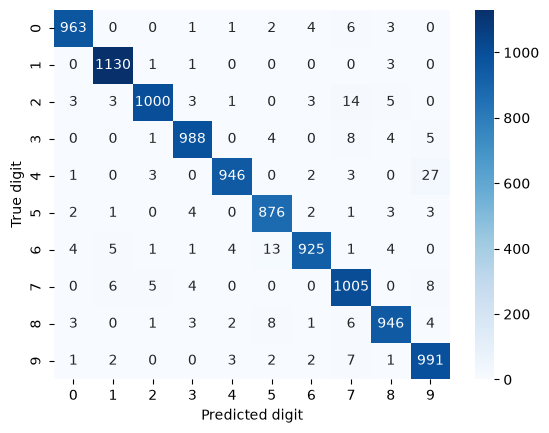

Test macro OvR AUC: 0.9995883957094366


best_model.pth дахин ачаалсан test accuracy: 0.977 checkpoint hash unchanged


Сонгосон загварын албан тестийн accuracy **0.9770**, weighted F1 **0.9770**, precision **0.9772**, recall **0.9770**, macro OvR AUC **0.99959**. Матрицын мөр нь бодит цифр, багана нь таамаглал; диагоналиас гаднах нүд нь андуурсан цифрүүдийг харуулна.

In [35]:
# evaluation of the best model
import sklearn.metrics as metrics
import hashlib
best_checkpoint_hash = hashlib.sha256(Path("best_model.pth").read_bytes()).hexdigest()

import seaborn as sns
with np.load("best_model_config.npz", allow_pickle=False) as z:
    model = SimpleNN(hidden_size1=int(z["hidden_size1"]), hidden_size2=int(z["hidden_size2"])).to(device)
model.load_state_dict(torch.load("best_model.pth", map_location=device, weights_only=True))
accuracy ,all_preds, all_labels = evaluate_model(model, test_loader, save=False)
confusion_matrix = metrics.confusion_matrix(all_labels, all_preds)
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
# other F1 score, precision, recall, etc. can be calculated using sklearn.metrics functions
f1_score = metrics.f1_score(all_labels, all_preds, average='weighted')
precision = metrics.precision_score(all_labels, all_preds, average='weighted')
recall = metrics.recall_score(all_labels, all_preds, average='weighted')
print(f"F1 Score: {f1_score:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
# AUC


plt.xlabel('Predicted digit'); plt.ylabel('True digit'); plt.show()
best_test_accuracy = accuracy
tuned_prob = probabilities(model, test_loader)
tuned_auc = metrics.roc_auc_score(all_labels, tuned_prob, multi_class='ovr', average='macro')
print('Test macro OvR AUC:', tuned_auc)
assert np.allclose(tuned_prob.sum(axis=1), 1, atol=1e-6)
assert np.array_equal(tuned_prob.argmax(axis=1), all_preds)
assert accuracy_score(all_labels, all_preds) == accuracy
assert evaluate_model(tuned_check, test_loader, verbose=False)[0] == accuracy
assert hashlib.sha256(Path('best_model.pth').read_bytes()).hexdigest() == best_checkpoint_hash
print('best_model.pth дахин ачаалсан test accuracy:', accuracy, 'checkpoint hash unchanged')
display(Markdown(f'Сонгосон загварын албан тестийн accuracy **{accuracy:.4f}**, weighted F1 **{f1_score:.4f}**, precision **{precision:.4f}**, recall **{recall:.4f}**, macro OvR AUC **{tuned_auc:.5f}**. Матрицын мөр нь бодит цифр, багана нь таамаглал; диагоналиас гаднах нүд нь андуурсан цифрүүдийг харуулна.'))


✅ Даалгавар 5 — 6-fold cross-validation, CUDA

MNIST-ийн 60000 сургалтын зурагт 6 хуваалт: fold бүрт 50000 сургалт, 10000 үнэлгээ. Тестийн 10000 зураг fold-д орохгүй. Шилдэг тохиргоог өмнөх validation хайлтаас авсан тул энэ CV нь бүрэн nested, хараат бус үнэлгээ биш. Fold бүрийг шинээр эхлүүлнэ; тогтмол эпох сургаж үнэлнэ. Fold-ийн checkpoint-уудыг хадгалж, бүх out-of-fold магадлалаар macro OvR AUC тооцно. Хамгийн өндөр fold accuracy-тай загварыг тусад нь хадгална; энэ нь бүх өгөгдөл дээр дахин сургасан загвар биш.

In [36]:
# KFold
from sklearn.model_selection import KFold
fold = KFold(n_splits=6, shuffle=True, random_state=42)
fold_rows = []
oof_prob = np.zeros((len(x_train),10), dtype=np.float64)
seen_oof = np.zeros(len(x_train), dtype=int)
fold_best_accuracy = -1.
fold_epochs = int(best_hyperparams['best_epoch'])
for fold_id, (fold_train_ids, fold_val_ids) in enumerate(fold.split(x_train, y_train),1):
    assert not np.intersect1d(fold_train_ids, fold_val_ids).size
    torch.manual_seed(42+fold_id)
    fold_model = SimpleNN(hidden_size1=best_hyperparams['hidden_size1'], hidden_size2=best_hyperparams['hidden_size2']).to(device)
    fold_train_loader = make_loader(Subset(train_dataset, fold_train_ids), best_hyperparams['batch_size'], True, seed=42+fold_id)
    fold_val_loader = make_loader(Subset(train_dataset, fold_val_ids), 512)
    if best_hyperparams['optimizer']=='SGD':
        fold_optimizer = SGD(fold_model.parameters(), lr=best_hyperparams['lr'], momentum=0.9, weight_decay=1e-5)
    else:
        fold_optimizer = AdamW(fold_model.parameters(), lr=best_hyperparams['lr'], weight_decay=1e-5)
    torch.cuda.synchronize(); t0 = perf_counter()
    train_model(fold_model, fold_train_loader, criterion, fold_optimizer, fold_epochs, verbose=False)
    fold_accuracy, fold_pred, fold_true = evaluate_model(fold_model, fold_val_loader, verbose=False)
    fold_prob = probabilities(fold_model, fold_val_loader)
    fold_auc = metrics.roc_auc_score(fold_true, fold_prob, multi_class='ovr', average='macro')
    oof_prob[fold_val_ids] = fold_prob
    seen_oof[fold_val_ids] += 1
    torch.cuda.synchronize(); elapsed = perf_counter()-t0
    state = cpu_state(fold_model)
    filename = f'kfold_fold_{fold_id}.pth'
    torch.save(state, filename)
    restored_fold = load_torch_model(filename, best_hyperparams['hidden_size1'], best_hyperparams['hidden_size2'])
    assert evaluate_model(restored_fold, fold_val_loader, verbose=False)[0] == fold_accuracy
    saved_model_files.append(filename)
    fold_rows.append(dict(fold=fold_id, train_size=len(fold_train_ids), val_size=len(fold_val_ids), accuracy=fold_accuracy, macro_auc=fold_auc, seconds=elapsed))
    if fold_accuracy > fold_best_accuracy:
        fold_best_accuracy, best_fold_id = fold_accuracy, fold_id
        best_fold_val_ids = fold_val_ids.copy()
        torch.save(state, 'kfold_best_model.pth')
    print('Fold',fold_id,'accuracy:',fold_accuracy,'macro AUC:',fold_auc,'seconds:',elapsed)
assert np.all(seen_oof==1)
fold_results = pd.DataFrame(fold_rows)
display(fold_results)
oof_accuracy = accuracy_score(y_train, oof_prob.argmax(axis=1))
oof_auc = metrics.roc_auc_score(y_train, oof_prob, multi_class='ovr', average='macro')
print('6-fold mean accuracy:', fold_results.accuracy.mean(), 'std:', fold_results.accuracy.std(ddof=1))
print('OOF accuracy:',oof_accuracy,'OOF macro OvR AUC:',oof_auc)
np.savez('kfold_best_config.npz', hidden_size1=best_hyperparams['hidden_size1'], hidden_size2=best_hyperparams['hidden_size2'], best_fold=best_fold_id, validation_ids=best_fold_val_ids, validation_accuracy=fold_best_accuracy, epochs=fold_epochs)
np.savez('kfold_results.npz', **{c:fold_results[c].to_numpy() for c in fold_results}, oof_probability=oof_prob, oof_accuracy=oof_accuracy, oof_macro_auc=oof_auc)
saved_model_files += ['kfold_best_model.pth','kfold_best_config.npz','kfold_results.npz']
with np.load('kfold_best_config.npz', allow_pickle=False) as z:
    cv_restored = load_torch_model('kfold_best_model.pth', z['hidden_size1'], z['hidden_size2'])
    verify_loader = make_loader(Subset(train_dataset, z['validation_ids']),512)
    assert evaluate_model(cv_restored, verify_loader, verbose=False)[0] == float(z['validation_accuracy'])
with np.load('kfold_results.npz', allow_pickle=False) as z:
    assert accuracy_score(y_train, z['oof_probability'].argmax(axis=1)) == float(z['oof_accuracy'])
    assert np.isclose(metrics.roc_auc_score(y_train, z['oof_probability'], multi_class='ovr', average='macro'), float(z['oof_macro_auc']))
print('kfold_best_model.pth дахин ачаалсан fold accuracy:',fold_best_accuracy)
display(Markdown(f'6 fold-ийн accuracy дундаж **{fold_results.accuracy.mean():.4f} ± {fold_results.accuracy.std(ddof=1):.4f}** (sample std). Бүх 60000 out-of-fold таамаглалын accuracy **{oof_accuracy:.4f}**, macro OvR AUC **{oof_auc:.5f}**. Шилдэг fold **{best_fold_id}**, accuracy **{fold_best_accuracy:.4f}**; зөвхөн түүний validation дүнгээр сонгосон. Хайлтад ашигласан validation нь CV сангийн дотор тул нийт үнэлгээг өөдрөг байж болохыг тооцно.'))


Fold 1 accuracy: 0.9774 macro AUC: 0.9995908051602151 seconds: 1.2466142299999774


Fold 2 accuracy: 0.9707 macro AUC: 0.9993823441724403 seconds: 1.2424046839987568


Fold 3 accuracy: 0.9742 macro AUC: 0.9991630327397912 seconds: 1.1060348089995387


Fold 4 accuracy: 0.974 macro AUC: 0.999374446620944 seconds: 1.2473945109995839


Fold 5 accuracy: 0.9735 macro AUC: 0.9994203684490008 seconds: 1.126993334000872


Fold 6 accuracy: 0.9742 macro AUC: 0.9994893981287467 seconds: 1.2507833099989512


,fold,train_size,val_size,accuracy,macro_auc,seconds
0,1,50000,10000,0.9774,0.999591,1.246614
1,2,50000,10000,0.9707,0.999382,1.242405
2,3,50000,10000,0.9742,0.999163,1.106035
3,4,50000,10000,0.9740,0.999374,1.247395
4,5,50000,10000,0.9735,0.999420,1.126993
5,6,50000,10000,0.9742,0.999489,1.250783


6-fold mean accuracy: 0.9739999999999999 std: 0.0021344788591129314
OOF accuracy: 0.974 OOF macro OvR AUC: 0.999357560964655
kfold_best_model.pth дахин ачаалсан fold accuracy: 0.9774


6 fold-ийн accuracy дундаж **0.9740 ± 0.0021** (sample std). Бүх 60000 out-of-fold таамаглалын accuracy **0.9740**, macro OvR AUC **0.99936**. Шилдэг fold **1**, accuracy **0.9774**; зөвхөн түүний validation дүнгээр сонгосон. Хайлтад ашигласан validation нь CV сангийн дотор тул нийт үнэлгээг өөдрөг байж болохыг тооцно.

✅ Даалгавар 6 — Албан тестийн мөрөөр нормчилсон төөрөгдлийн матриц

Хайлтаар сонгосон best_model-ийг үнэлнэ; KFold-ийн сүүлийн fold загварыг санамсаргүй хэрэглэхгүй. Ангиуд 0–9; мөр бүрийн нийлбэр 1.

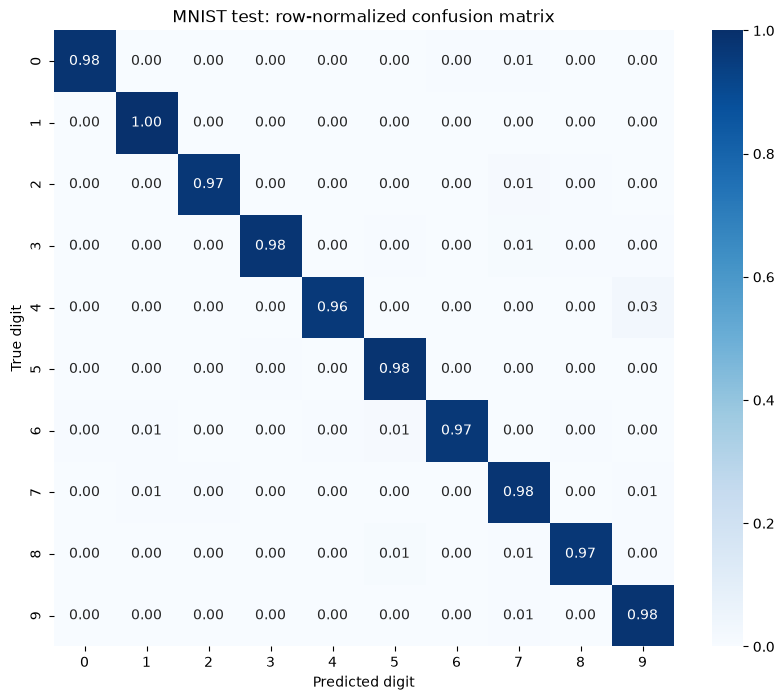

Матрицын нийт дээж: 10000 test accuracy: 0.977


Мөр бүрийн хувь 1-д нийлж байна. Диагоналын утга нь цифр тус бүрийн recall юм. Нийт 10000 тестийн зураг дээр accuracy **0.9770**; тоогоор үзүүлсэн өмнөх матрицтай ижил таамаглал ашигласан.

In [37]:
from sklearn.metrics import confusion_matrix
import seaborn as sn
import pandas as pd
y_pred, y_true = [], []
model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        output = model(inputs.to(device))
        y_pred.extend(output.argmax(dim=1).cpu().numpy())
        y_true.extend(labels.numpy())
cf_matrix = confusion_matrix(y_true, y_pred, labels=range(10))
classes = list(range(10))
row_totals = cf_matrix.sum(axis=1, keepdims=True)
normalized = np.divide(cf_matrix, row_totals, out=np.zeros_like(cf_matrix, dtype=float), where=row_totals!=0)
df_cm = pd.DataFrame(normalized, index=classes, columns=classes)
np.testing.assert_allclose(normalized.sum(axis=1), 1)
assert accuracy_score(y_true, y_pred) == best_test_accuracy
plt.figure(figsize=(10,8))
sn.heatmap(df_cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.xlabel('Predicted digit'); plt.ylabel('True digit'); plt.title('MNIST test: row-normalized confusion matrix')
plt.show()
print('Матрицын нийт дээж:',cf_matrix.sum(), 'test accuracy:',accuracy_score(y_true,y_pred))
display(Markdown(f'Мөр бүрийн хувь 1-д нийлж байна. Диагоналын утга нь цифр тус бүрийн recall юм. Нийт 10000 тестийн зураг дээр accuracy **{best_test_accuracy:.4f}**; тоогоор үзүүлсэн өмнөх матрицтай ижил таамаглал ашигласан.'))


✅ Даалгавар 1–6 — Хадгалсан загваруудын эцсийн бүртгэл ба GPU санах ой

In [38]:
for filename in saved_model_files:
    path = Path(filename)
    assert path.is_file() and path.stat().st_size < 50_000_000
    if path.suffix=='.npz':
        with np.load(path, allow_pickle=False) as z:
            assert z.files
    elif path.suffix=='.pth':
        state = torch.load(path, map_location='cpu', weights_only=True)
        assert state and all(torch.isfinite(t).all() for t in state.values())
    print(filename, path.stat().st_size, 'bytes: OK')
peak_gb = torch.cuda.max_memory_allocated()/1024**3
print('PyTorch peak allocated GB:', peak_gb)
assert peak_gb < 14
print('Бүх',len(saved_model_files),'файл ачаалагдсан; checkpoint-уудын accuracy-г хадгалах үед дахин баталсан.')


numpy_nn_weights.npz 876082 bytes: OK
cupy_nn_weights.npz 875694 bytes: OK
torch_baseline.pth 942261 bytes: OK
torch_baseline_config.npz 1354 bytes: OK
tuning_trial_0.pth 440373 bytes: OK
tuning_trial_1.pth 942261 bytes: OK
tuning_trial_2.pth 942261 bytes: OK
tuning_trial_3.pth 942261 bytes: OK
best_model.pth 942197 bytes: OK
best_model_config.npz 2356 bytes: OK
tuning_results.npz 2894 bytes: OK
kfold_fold_1.pth 942229 bytes: OK
kfold_fold_2.pth 942229 bytes: OK
kfold_fold_3.pth 942229 bytes: OK
kfold_fold_4.pth 942229 bytes: OK
kfold_fold_5.pth 942229 bytes: OK
kfold_fold_6.pth 942229 bytes: OK
kfold_best_model.pth 942293 bytes: OK
kfold_best_config.npz 81598 bytes: OK
kfold_results.npz 4802586 bytes: OK
PyTorch peak allocated GB: 0.03335142135620117
Бүх 20 файл ачаалагдсан; checkpoint-уудын accuracy-г хадгалах үед дахин баталсан.
